# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Hernando, Claire Marie M.
- _Student No._: 2024-12904
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![Plots for function 1](f_1.png) 
***Figure 1** shows the (a) Log-log plot resulting from the 4 different Integration Methods applied to $f_1(x)$ and (b) the results of the Monte Carlo simulation of the bounded points of the same function.*

![Plots for function 2](f_2.png) 
***Figure 2** shows the (a) Log-log plot resulting from the 4 different Integration Methods applied to $f_2(x)$ and (b) the results of the Monte Carlo simulation of the bounded points of the same function.*

![Plots for function 3](f_3.png) 
***Figure 3** shows the (a) Log-log plot resulting from the 4 different Integration Methods applied to $f_3(x)$ and (b) the results of the Monte Carlo simulation of the bounded points of the same function.*

### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

**1.) Explain the figures.**

The figures illustrate deterministic Newton-Cotes and stochastic Monte Carlo integration methods across three functions.

Subfigures (a) display log-log error convergence, confirming the following theoretical power-law decays: $\mathcal{O}(h^2)$ for trapezoidal, $\mathcal{O}(h^4)$ for Simpson's rules, and $\mathcal{O}(N^{-1/2})$ for Monte Carlo. Specifically, Figures 1.a and 3.a show Simpson's fourth-order superiority over second-order trapezoidal integration. Meanwhile, Figure 2.a highlights Simpson's exact convergence to machine precision for polynomials of degree $\le 3$, leaving only rounding errors due to zero theoretical truncation. Across all error plots, Monte Carlo exhibits stochastic fluctuations inherent to random sampling, independent of integrand smoothness or polynomial degree.

On the other hand, Subfigures (b) demonstrate bounded rejection sampling with accurate signed-area handling. Points above the x-axis are blue and points below are red, with Figure 1.b showing exclusively blue points due to its strictly non-negative domain.

**2.) Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?**

We arrive at an integration value using Monte Carlo simulation because of probabilistic sampling and the Law of Large Numbers. By randomly generating points within a known domain and calculating the fraction that fall beneath the curve, the simulation estimates the proportional area of the integral relative to the entire bounding box. 

Also, Newton-Cotes methods are more appropriate than Monte Carlo methods since the former can achieve rapid deterministic convergence ($\mathcal{O}(h^2)$ to $\mathcal{O}(h^4)$) or exactness for low-degree polynomials, requiring fewer function evaluations to reach high precision. Unlike Monte Carlo, they do not rely on slow stochastic convergence ($\mathcal{O}(N^{-1/2})$), and do not require massive sample sizes to achieve accuracy. 

### Other comments
- I plotted the log-log plot and the Monte Carlos simulation for each function side-by-side into a 1x2 subplot so it won't be hard for me to compile and compare the graphs. 


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

Report Figures (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

Report discussion: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [4]:
import numpy as np
import matplotlib.pyplot as plt
import math 
from scipy import integrate 

##### 1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$

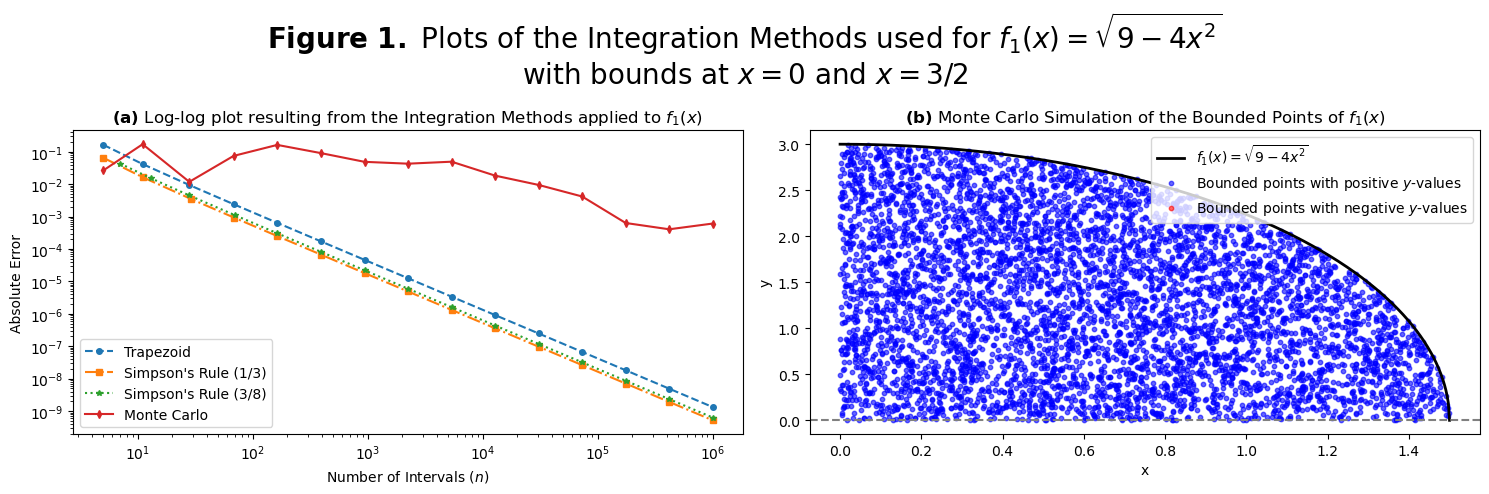

In [100]:
# Setting-up the function 
def f_1(x):
    return np.sqrt(np.maximum(0, 9 - (4*x**2)))

# Setting parameters
a = 0 
b = 3/2
n = 25

# Generate range of n values
ns = np.logspace(0.7, 6.0, 15, dtype=int)
ns_1_3 = np.where(ns % 2 == 0, ns + 1, ns) # Looks at every element in the array
rem_ns = (ns - 1) % 3
ns_3_8 = np.where(rem_ns != 0, ns + (3 - rem_ns), ns) 
ns_mc = np.unique(ns)

# Setting up formula for integration
# Trapezoidal Integration
def trapezoid (f_1, a, b, n): # Pattern: 1/2, 1, 1, ...., 1/2 
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h
    cs = np.ones(n) 
    cs[0] = 0.5 
    cs[-1] = 0.5 
    contribs = cs * f_1(xs)
    return h * np.sum(contribs)

# 1/3 Simpson's Rule
def simpson_1_3 (f_1, a, b, n): # Pattern: 1, 4, 2, 4, 2, ..., 1
    if n % 2 == 0:
        n += 1 
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h 
    cs = 2 * np.ones(n)
    cs[0] = 1
    cs[-1] = 1
    cs[1::2] = 4
    contribs = cs * f_1(xs) 
    return (1/3) * h * np.sum(contribs)

# 3/8 Simpson's Rule
def simpson_3_8 (f_1, a, b, n): # Pattern: 1, 3, 3, 2, 3, 3, ..., 1
    rem = (n - 1) % 3
    if rem != 0:
        n += (3 - rem) # (n-1) must be a multiple of 3 
    h = (b - a) / (n -1) 
    xs = a + np.arange(n) * h 
    cs = 3 * np.ones(n)
    cs[0] = 1
    cs[-1] = 1
    cs[3:-1:3] = 2
    contribs = cs * f_1(xs)
    return (3/8) * h * np.sum(contribs)

# Monte Carlo 
def montecarlo (f_1, a, b, n, option="uniform"):
    np.random.seed(314159)
    us = np.random.uniform(a, b, n)

    if option=="uniform":
        fs = f_1(us) 
    else:
        c0 = 4 - 2 * np.sqrt(2)
        c1 = -6 + 4 * np.sqrt(2)
        xs = (-c0 + np.sqrt(2 * c1 * us + c0**2))/c1
        fs = f(xs)/(c0 + c1*xs) 

    fbar, err = stats(fs) 
    return (b -a) * fbar, (b - a) * err

def stats(fs):
    n = fs.size
    fbar = np.sum(fs) / n
    fsq = np.sum(fs**2) / n
    varfbar = (fsq - fbar**2) / (n-1) 
    return fbar, np.sqrt(varfbar)

# Solving for true value
true_val = integrate.quad(f_1, a, b)[0]

# Solving for the absolute error
trapezoid_abs_error = [np.abs(trapezoid(f_1, a, b, n) - true_val) for n in ns]
simpson_1_3_abs_error = [np.abs(simpson_1_3(f_1, a, b, n) - true_val) for n in ns]
simpson_3_8_abs_error = [np.abs(simpson_3_8(f_1, a, b, n) - true_val) for n in ns]
montecarlo_abs_error = [np.abs(montecarlo(f_1, a, b, n, option="uniform")[0] - true_val) for n in ns]

# Data for Monte Carlo Scatter Plot
# Generating random x and y for testing bounds
n_plot = 10000
x_rand = np.random.uniform(a, b, n_plot)

# Finding y_min and y_max of the function to bound y_rand properly 
x_smooth = np.linspace(a, b, 500)
y_smooth = f_1(x_smooth)
y_min = np.min(y_smooth)
y_max = np.max(y_smooth)

# Padding so points won't touch borders
y_padding = 0.2 * (abs(y_max - y_min) if y_max != y_min else 1.0) 
y_rand = np.random.uniform(min(0, y_min) - y_padding, max(0, y_max) + y_padding, n_plot)

# Evaluate function at random x points
y_curve = f_1(x_rand)

# Assigning colors to points below and above the x axis
blue_mask = (y_rand >= 0) & (y_rand <= y_curve)
red_mask = (y_rand <=0) & (y_rand >= y_curve)

# Plotting into a 1x2 subplot
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(ns, trapezoid_abs_error, label="Trapezoid", marker="o", markersize=4, linestyle='--')
ax[0].plot(ns_1_3, simpson_1_3_abs_error, label="Simpson's Rule (1/3)", marker="s", markersize=4, linestyle='-.')
ax[0].plot(ns_3_8, simpson_3_8_abs_error, label="Simpson's Rule (3/8)", marker="*", markersize=4, linestyle=':')
ax[0].plot(ns_mc, montecarlo_abs_error, label="Monte Carlo", marker="d", markersize=4, linestyle='-')
ax[0].set_xscale('log')
ax[0].set_xlabel("Number of Intervals ($n$)")
ax[0].set_yscale('log')
ax[0].set_ylabel("Absolute Error")
ax[0].set_title(r"$\bf{(a)}$ Log-log plot resulting from the Integration Methods applied to $f_1(x)$")
ax[0].legend()

ax[1].plot(x_smooth, y_smooth, 'k-', label=r"$f_1(x) = \sqrt{9 - 4x^2}$", linewidth=2)
ax[1].axhline(0, color='gray', linestyle='--')
ax[1].scatter(x_rand[blue_mask], y_rand[blue_mask], color="blue", s=10, alpha=0.6, label="Bounded points with positive $y$-values")
ax[1].scatter(x_rand[red_mask], y_rand[red_mask], color="red", s=10, alpha=0.6, label="Bounded points with negative $y$-values")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_title(r"$\bf{(b)}$ Monte Carlo Simulation of the Bounded Points of $f_1(x)$")
ax[1].legend()

plt.suptitle(r"$\bf{Figure\ 1.}$ Plots of the Integration Methods used for $f_1(x) = \sqrt{9 - 4x^2}$" + "\n" + r"with bounds at $x=0$ and $x=3/2$", fontsize=20)

plt.tight_layout()
plt.savefig("f_1.png", dpi=150)
plt.show()

##### 2. $$ y = -x^2 + 1, x=-2, x=2 $$

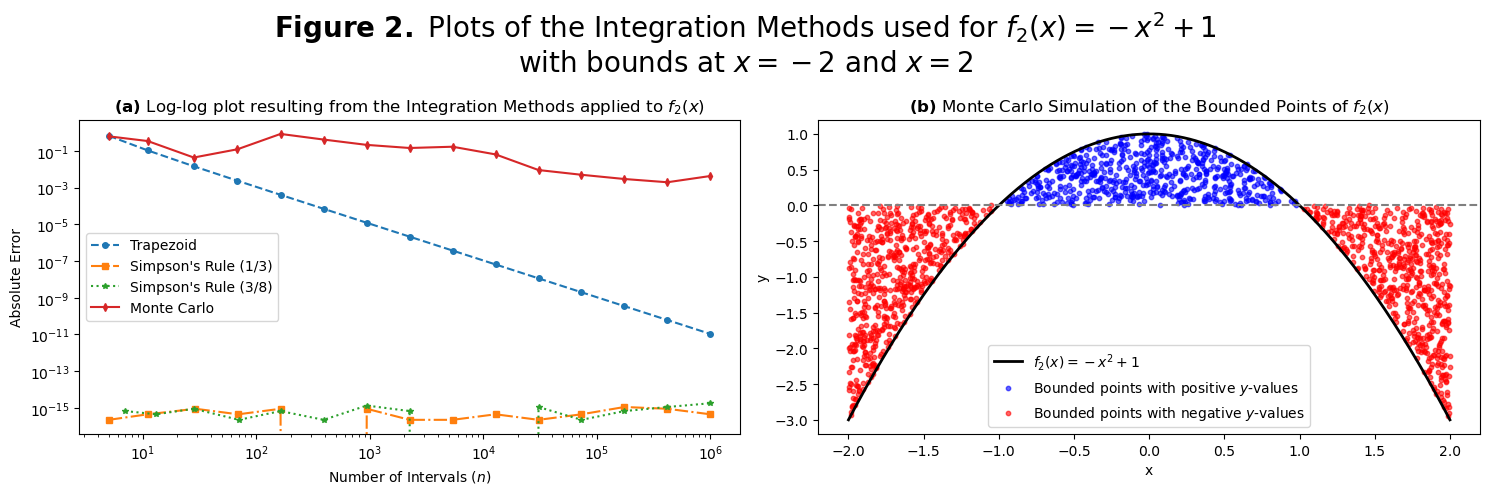

In [101]:
# Setting-up the function 
def f_2(x):
    return -x**2 + 1
 
# Setting parameters
a = -2
b = 2
n = 25

# Generate range of n values
ns = np.logspace(0.7, 6.0, 15, dtype=int)
ns_1_3 = np.where(ns % 2 == 0, ns + 1, ns) # Looks at every element in the array
rem_ns = (ns - 1) % 3
ns_3_8 = np.where(rem_ns != 0, ns + (3 - rem_ns), ns) 
ns_mc = np.unique(ns)

# Setting up formula for integration
# Trapezoidal Integration
def trapezoid (f_2, a, b, n): # Pattern: 1/2, 1, 1, ...., 1/2 
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h
    cs = np.ones(n) 
    cs[0] = 0.5 
    cs[-1] = 0.5 
    contribs = cs * f_2(xs)
    return h * np.sum(contribs)

# 1/3 Simpson's Rule
def simpson_1_3 (f_2, a, b, n): # Pattern: 1, 4, 2, 4, 2, ..., 1
    if n % 2 == 0:
        n += 1 
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h 
    cs = 2 * np.ones(n)
    cs[0] = 1
    cs[-1] = 1
    cs[1::2] = 4
    contribs = cs * f_2(xs) 
    return (1/3) * h * np.sum(contribs)

# 3/8 Simpson's Rule
def simpson_3_8 (f_2, a, b, n): # Pattern: 1, 3, 3, 2, 3, 3, ..., 1
    rem = (n - 1) % 3
    if rem != 0:
        n += (3 - rem) # (n-1) must be a multiple of 3 
    h = (b - a) / (n -1) 
    xs = a + np.arange(n) * h 
    cs = 3 * np.ones(n)
    cs[0] = 1
    cs[-1] = 1
    cs[3:-1:3] = 2
    contribs = cs * f_2(xs)
    return (3/8) * h * np.sum(contribs)

# Monte Carlo 
def montecarlo (f_2, a, b, n, option="uniform"):
    np.random.seed(314159)
    us = np.random.uniform(a, b, n)

    if option=="uniform":
        fs = f_2(us) 
    else:
        c0 = 4 - 2 * np.sqrt(2)
        c1 = -6 + 4 * np.sqrt(2)
        xs = (-c0 + np.sqrt(2 * c1 * us + c0**2))/c1
        fs = f(xs)/(c0 + c1*xs) 

    fbar, err = stats(fs) 
    return (b -a) * fbar, (b - a) * err

def stats(fs):
    n = fs.size
    fbar = np.sum(fs) / n
    fsq = np.sum(fs**2) / n
    varfbar = (fsq - fbar**2) / (n-1) 
    return fbar, np.sqrt(varfbar)

# Solving for true value
true_val = integrate.quad(f_2, a, b)[0]

# Solving for the absolute error
trapezoid_abs_error = [np.abs(trapezoid(f_2, a, b, n) - true_val) for n in ns]
simpson_1_3_abs_error = [np.abs(simpson_1_3(f_2, a, b, n) - true_val) for n in ns]
simpson_3_8_abs_error = [np.abs(simpson_3_8(f_2, a, b, n) - true_val) for n in ns]
montecarlo_abs_error = [np.abs(montecarlo(f_2, a, b, n, option="uniform")[0] - true_val) for n in ns]

# Data for Monte Carlo Scatter Plot
# Generating random x and y for testing bounds
n_plot = 10000
x_rand = np.random.uniform(a, b, n_plot)

# Finding y_min and y_max of the function to bound y_rand properly 
x_smooth = np.linspace(a, b, 500)
y_smooth = f_2(x_smooth)
y_min = np.min(y_smooth)
y_max = np.max(y_smooth)

# Padding so points won't touch borders
y_padding = 0.2 * (abs(y_max - y_min) if y_max != y_min else 1.0) 
y_rand = np.random.uniform(min(0, y_min) - y_padding, max(0, y_max) + y_padding, n_plot)

# Evaluate function at random x points
y_curve = f_2(x_rand)

# Assigning colors to points below and above the x axis
blue_mask = (y_rand >= 0) & (y_rand <= y_curve)
red_mask = (y_rand <=0) & (y_rand >= y_curve)

# Plotting into a 1x2 subplot
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(ns, trapezoid_abs_error, label="Trapezoid", marker="o", markersize=4, linestyle='--')
ax[0].plot(ns_1_3, simpson_1_3_abs_error, label="Simpson's Rule (1/3)", marker="s", markersize=4, linestyle='-.')
ax[0].plot(ns_3_8, simpson_3_8_abs_error, label="Simpson's Rule (3/8)", marker="*", markersize=4, linestyle=':')
ax[0].plot(ns_mc, montecarlo_abs_error, label="Monte Carlo", marker="d", markersize=4, linestyle='-')
ax[0].set_xscale('log')
ax[0].set_xlabel("Number of Intervals ($n$)")
ax[0].set_yscale('log')
ax[0].set_ylabel("Absolute Error")
ax[0].set_title(r"$\bf{(a)}$ Log-log plot resulting from the Integration Methods applied to $f_2(x)$")
ax[0].legend()

ax[1].plot(x_smooth, y_smooth, 'k-', label=r"$f_2(x) = -x^2 + 1$", linewidth=2)
ax[1].axhline(0, color='gray', linestyle='--')
ax[1].scatter(x_rand[blue_mask], y_rand[blue_mask], color="blue", s=10, alpha=0.6, label="Bounded points with positive $y$-values")
ax[1].scatter(x_rand[red_mask], y_rand[red_mask], color="red", s=10, alpha=0.6, label="Bounded points with negative $y$-values")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_title(r"$\bf{(b)}$ Monte Carlo Simulation of the Bounded Points of $f_2(x)$")
ax[1].legend()

plt.suptitle(r"$\bf{Figure\ 2.}$ Plots of the Integration Methods used for $f_2(x) = -x^2 + 1$" + "\n" + r"with bounds at $x=-2$ and $x=2$", fontsize=20)

plt.tight_layout()
plt.savefig("f_2.png", dpi=150)
plt.show()

##### 3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

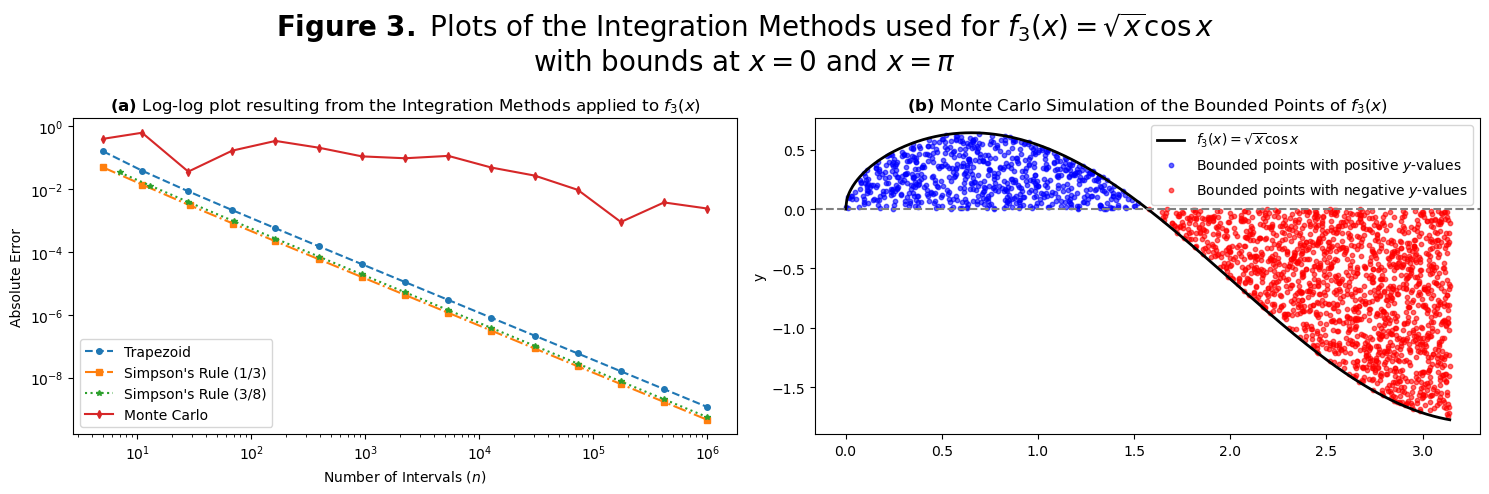

In [102]:
# Setting-up the function 
def f_3(x):
    return np.sqrt(np.maximum(0, x)) * np.cos(x)
 
# Setting parameters
a = 0
b = np.pi
n = 25

# Generate range of n values
ns = np.logspace(0.7, 6.0, 15, dtype=int)
ns_1_3 = np.where(ns % 2 == 0, ns + 1, ns) # Looks at every element in the array
rem_ns = (ns - 1) % 3
ns_3_8 = np.where(rem_ns != 0, ns + (3 - rem_ns), ns) 
ns_mc = np.unique(ns) # To remove any duplicate integers 

# Setting up formula for integration
# Trapezoidal Integration
def trapezoid (f_3, a, b, n): # Pattern: 1/2, 1, 1, ...., 1/2 
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h
    cs = np.ones(n) 
    cs[0] = 0.5 
    cs[-1] = 0.5 
    contribs = cs * f_3(xs)
    return h * np.sum(contribs)

# 1/3 Simpson's Rule
def simpson_1_3 (f_3, a, b, n): # Pattern: 1, 4, 2, 4, 2, ..., 1
    if n % 2 == 0:
        n += 1 
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h 
    cs = 2 * np.ones(n)
    cs[0] = 1
    cs[-1] = 1
    cs[1::2] = 4
    contribs = cs * f_3(xs) 
    return (1/3) * h * np.sum(contribs)

# 3/8 Simpson's Rule
def simpson_3_8 (f_3, a, b, n): # Pattern: 1, 3, 3, 2, 3, 3, ..., 1
    rem = (n - 1) % 3
    if rem != 0:
        n += (3 - rem) # (n-1) must be a multiple of 3 
    h = (b - a) / (n -1) 
    xs = a + np.arange(n) * h 
    cs = 3 * np.ones(n)
    cs[0] = 1
    cs[-1] = 1
    cs[3:-1:3] = 2
    contribs = cs * f_3(xs)
    return (3/8) * h * np.sum(contribs)

# Monte Carlo 
def montecarlo (f_3, a, b, n, option="uniform"):
    np.random.seed(314159)
    us = np.random.uniform(a, b, n)

    if option=="uniform":
        fs = f_3(us) 
    else:
        c0 = 4 - 2 * np.sqrt(2)
        c1 = -6 + 4 * np.sqrt(2)
        xs = (-c0 + np.sqrt(2 * c1 * us + c0**2))/c1
        fs = f(xs)/(c0 + c1*xs) 

    fbar, err = stats(fs) 
    return (b -a) * fbar, (b - a) * err

def stats(fs):
    n = fs.size
    fbar = np.sum(fs) / n
    fsq = np.sum(fs**2) / n
    varfbar = (fsq - fbar**2) / (n-1) 
    return fbar, np.sqrt(varfbar)

# Solving for true value
true_val = integrate.quad(f_3, a, b)[0]

# Solving for the absolute error
trapezoid_abs_error = [np.abs(trapezoid(f_3, a, b, n) - true_val) for n in ns]
simpson_1_3_abs_error = [np.abs(simpson_1_3(f_3, a, b, n) - true_val) for n in ns]
simpson_3_8_abs_error = [np.abs(simpson_3_8(f_3, a, b, n) - true_val) for n in ns]
montecarlo_abs_error = [np.abs(montecarlo(f_3, a, b, n, option="uniform")[0] - true_val) for n in ns]

# Data for Monte Carlo Scatter Plot
# Generating random x and y for testing bounds
n_plot = 10000
x_rand = np.random.uniform(a, b, n_plot)

# Finding y_min and y_max of the function to bound y_rand properly 
x_smooth = np.linspace(a, b, 500)
y_smooth = f_3(x_smooth)
y_min = np.min(y_smooth)
y_max = np.max(y_smooth)

# Padding so points won't touch borders and the graph won't get clipped near the borders
y_padding = 0.2 * (abs(y_max - y_min) if y_max != y_min else 1.0) 
y_rand = np.random.uniform(min(0, y_min) - y_padding, max(0, y_max) + y_padding, n_plot)

# Evaluate function at random x points
y_curve = f_3(x_rand)

# Assigning colors to points below and above the x axis
blue_mask = (y_rand >= 0) & (y_rand <= y_curve)
red_mask = (y_rand <=0) & (y_rand >= y_curve)

# Plotting into a 1x2 subplot
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(ns, trapezoid_abs_error, label="Trapezoid", marker="o", markersize=4, linestyle='--')
ax[0].plot(ns_1_3, simpson_1_3_abs_error, label="Simpson's Rule (1/3)", marker="s", markersize=4, linestyle='-.')
ax[0].plot(ns_3_8, simpson_3_8_abs_error, label="Simpson's Rule (3/8)", marker="*", markersize=4, linestyle=':')
ax[0].plot(ns_mc, montecarlo_abs_error, label="Monte Carlo", marker="d", markersize=4, linestyle='-')
ax[0].set_xscale('log')
ax[0].set_xlabel("Number of Intervals ($n$)")
ax[0].set_yscale('log')
ax[0].set_ylabel("Absolute Error")
ax[0].set_title(r"$\bf{(a)}$ Log-log plot resulting from the Integration Methods applied to $f_3(x)$")
ax[0].legend()

ax[1].plot(x_smooth, y_smooth, 'k-', label=r"$f_3(x) = \sqrt{x}\cos{x}$", linewidth=2)
ax[1].axhline(0, color='gray', linestyle='--')
ax[1].scatter(x_rand[blue_mask], y_rand[blue_mask], color="blue", s=10, alpha=0.6, label="Bounded points with positive $y$-values")
ax[1].scatter(x_rand[red_mask], y_rand[red_mask], color="red", s=10, alpha=0.6, label="Bounded points with negative $y$-values")
ax[1].set_ylabel("y")
ax[1].set_title(r"$\bf{(b)}$ Monte Carlo Simulation of the Bounded Points of $f_3(x)$")
ax[1].legend()

plt.suptitle(r"$\bf{Figure\ 3.}$ Plots of the Integration Methods used for $f_3(x) = \sqrt{x}\cos{x}$" + "\n" + r"with bounds at $x=0$ and $x=\pi$", fontsize=20)

plt.tight_layout()
plt.savefig("f_3.png", dpi=150)
plt.show()